In [ ]:
all_results = []
for (orbitNumber, year, month, day) in [
    ('01087', '2024', '08', '06'),
    ('06486', '2025', '07', '19'), 
    #('06564E', '2025', '07', '24'), 
    ('06595', '2025', '07', '26')
    ]:
    region = 'SEP'
    frame = 'E'
    orbit = f'{orbitNumber}{frame}'
    computed_orbits = []

    args = region, frame, orbitNumber, orbit, year, month, day, computed_orbits

    from step10_run_judge import process_single_orbit
    results = process_single_orbit(args)
    all_results.append(results)

Processing orbit 01087E
Loading MCOP data...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/06/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/06/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E.h5
Orbit: 01087E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/06/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_202509

In [9]:
cot_data = results['plot_data']['cot_data']

In [6]:
along_track = results['plot_data']['along_track_coords']
across_track = results['plot_data']['across_track_coords']

In [7]:
across_track

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [10]:
cot_data.shape

(4908, 384)

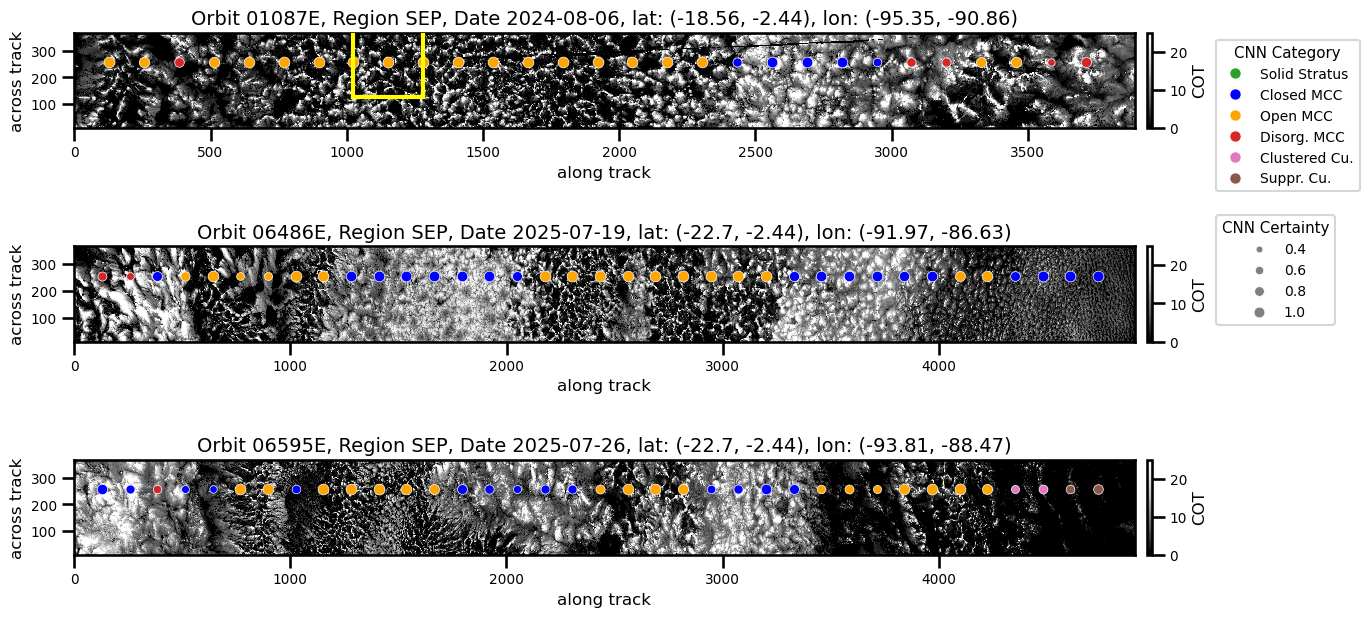

In [27]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import xarray as xr


sns.set_context('talk', font_scale=0.6)
fig, axs = plt.subplots(3, 1, figsize=(14,2.1*3))

for i, results in enumerate(all_results):
    plot_data = results['plot_data']
    ax = axs[i]

    # Plot background data using imshow instead of xarray plot
    along_track = plot_data['along_track_coords']
    across_track = plot_data['across_track_coords']

    # clean COT data by removing pixels that are all NaN along the along_track dimension
    cot_data = plot_data['cot_data']
    cot_data = xr.DataArray(cot_data, coords=[along_track, across_track], dims=['along_track', 'across_track'])
    valid_pixels = ~cot_data.isnull().all(dim='along_track') 
    cot_data = cot_data.where(valid_pixels, drop=True)
    cot_data = cot_data.fillna(0)
    #cot_data = np.where(np.isnan(cot_data), 0, cot_data)

    # Plot COT data
    cot_plot = cot_data.T.plot(ax=ax, vmin=0, vmax=25, cmap='Greys_r', add_colorbar=False)
    #cot_plot = ax.imshow(cot_data.T, aspect='auto', 
    #                        extent=[along_track[0], along_track[-1], 
    #                                across_track[0], across_track[-1]],
    #                        vmin=0, vmax=25, cmap='Greys_r')
    cbar0 = plt.colorbar(cot_plot, ax=ax, pad=0.01)
    cbar0.set_label('COT', fontsize=12)
    ax.set_ylabel('across track', fontsize=12)
    ax.set_xlabel('along track', fontsize=12)

    # Add scatter plot on top
    df_plot = plot_data['df_plot']
    hue = [6 if row['ice_flag'] > 0.01 else row['cats'] for row in df_plot]
    colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#e377c2', '#8c564b', 'white']
    colors = ['#2ca02c', 'blue', 'orange', '#d62728', '#e377c2', '#8c564b', 'white']
    cats_names = ['Solid Stratus', 'Closed MCC', 'Open MCC', 'Disorg. MCC', 'Clustered Cu.', 'Suppr. Cu.', 'Ice cloud']
    palette = {i: colors[i] for i in range(7)}

    for j, row in enumerate(df_plot):
        color = palette[hue[j]]
        size = row['cert'] * 60
        ax.scatter(row['along_track_mid'], plot_data['across_track_dim'] - 128, 
                        c=color, s=size, edgecolors='white', linewidth=0.5)
        
        # add rectangle showing the size of the 128 x 128 km scenes
        if i == 0 and j == 8:
            import matplotlib.patches as mpatches
            x_mid,y_mid = (row['along_track_mid'], plot_data['across_track_dim'] - 128)
            rect1 = mpatches.Rectangle((x_mid - 128, y_mid - 128), (128*2), (128*2), linewidth=3, edgecolor='yellow', facecolor='none', zorder=3)
            ax.add_patch(rect1)


    ax.set_title(f'Orbit {plot_data["orbit"]}, Region {plot_data["region"]}, Date {plot_data["year"]}-{plot_data["month"]}-{plot_data["day"]}, lat: {plot_data["lat_range"]}, lon: {plot_data["lon_range"]}', 
                    fontsize=14)

legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=cats_names[i], 
                        markerfacecolor=colors[i], markersize=8, markeredgecolor='white', markeredgewidth=0.5) 
                    for i in range(6)]
cert_levels = [0.4, 0.6, 0.8, 1.0]
legend_handles_cert = [plt.Line2D([0], [0], marker='o', color='w', label=f'{cert_level:.1f}', 
                        markerfacecolor='gray', markersize=np.sqrt(cert_level * 60), markeredgecolor='white', markeredgewidth=0.5)
                        for cert_level in cert_levels]
axs[0].legend(handles=legend_handles , title='CNN Category', bbox_to_anchor=(1.07, 1), loc='upper left', fontsize=10)
axs[1].legend(handles=legend_handles_cert, title='CNN Certainty', bbox_to_anchor=(1.07, 1.4), loc='upper left', fontsize=10)
fig.tight_layout()
plt.savefig(f'./../analysis/figures/example_judge_msi.png', dpi=100, bbox_inches='tight')